# DDRL Actor-Critic {#sec-ddrlac}

In this section, we provide functions that are specific to the Actor-Critic version of Distributional Deterministic Reinforcement Learning.

First, we import everything necessary:

In [1]:
 #| default_exp Agents.DDRLActorCritic

In [2]:
 #| hide
# Imports for the nbdev development environment
import nbdev
from nbdev.showdoc import *
from fastcore.basics import patch

In [3]:
 #| export
import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

import itertools as it

from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *
from pyCRLD.Utils.Helpers import compute_stationarydistribution

from pyDDRL.Agents.DDRLBase import DDRLBase

from pyDDRL.Agents.Methods import quantile, expectile, weights

In [4]:
# imports for this notebook
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from pyCRLD.Utils import FlowPlot as fp

# test environment
from pyDDRL.Environments.RiskRewardDilemma import RiskRewardDilemma

# regular Actor-Critic agent
from pyCRLD.Agents.StrategyActorCritic import stratAC

## Test environment

We use a risk-reward dilemma as a test environment. In this task, the agent can choose between a high-risk, high-gain option, and a low-risk, low-gain option. More precisely, we give our environment the following structure:

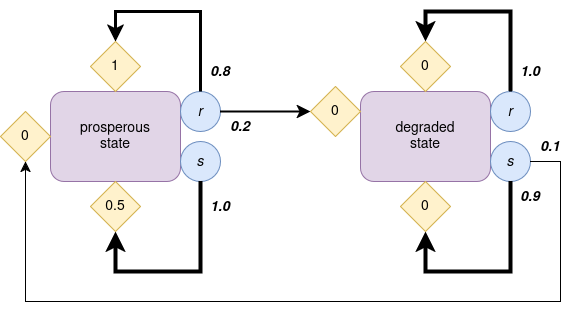

If an agent chooses the risky action $r$ in the prosperous state, it gets a higher reward. But there is a probability that it transitions to a degraded state, where it gets no reward. The only way to escape this degraded state is to choose the safe action, $s$.

In [5]:
# Define environment
env = RiskRewardDilemma(pc=0.2, pr=0.1, rc=0.5, rr=1, rd=0)
env

RiskRewardDilemma_0.2_0.1_0.5_1_0

## DDRL Actor-Critic class

Now, we can define the DDRL Actor-Critic class:

In [6]:
 #| export
class DDRLActorCritic(DDRLBase):
    """
    Base class for Actor-Critic version of DDRL in strategy space.        
    """
    
    def __init__(self,
                 env,
                 **kwargs):
    
        super().__init__(env, **kwargs)

We consider the following agent-environment interface:
* 1 agent with learning rate $\alpha=0.1$ and discount factor $\gamma=0.4$;
* playing the aforementioned risk-reward dilemma.

In [7]:
aei = DDRLActorCritic(env,
                      nr_reward_bins=29,
                      discretization_sigma=0.1,
                      learning_rates=0.1,
                      discount_factors=0.4,
                      Rmin=-0.5,
                      Rmax=1.5,
                      use_prefactor=True)

## Computing distributions in DDRL-SARSA

Now we can compute and plot all the distributions we need.

### state-action value distribution $V^{i,s,a^i,\acute v}$

Just like state values, state-action values conform to the Bellman equation. Therefore, we can obtain the state-action value distribution for agent $i$, action $a^i$ and state $s$, from the next-state Q-value distribution for $(i,a,s)$, the reward distribution for $(i,a,s)$, and the smoothed Bellman Kronecker delta:
$$V^{i,s,a,v} =  \sum_{r, \acute v} \delta^{i,v,r,\acute v} R^{i,s,a,r} \cdot {}^{next}V^{i,s,a,\acute v}$$

In [8]:
 #| export
@partial(jit, static_argnums=0)        
def Visav(self:DDRLActorCritic,
          Xisa:jnp.ndarray, # Joint strategy
          Tisas:jnp.ndarray=None, # Optional transition for speed-up
          ) -> jnp.ndarray:  # Average state-action values
    """
    Compute Q-value distribution Visaq, given joint strategy `Xisa`.
    """
    Risar = self.Risar(Xisa)
    b_ivrv_ = self.b_ivrv_
    Visv = self.Visv(Xisa) 
    Tisas = self.Tisas(Xisa) if Tisas is None else Tisas 

    i = 0; s = 1; a = 2; s_ = 3; v = 4; v_ = 5; r = 6
    nextVisav = jnp.einsum(Tisas, [i,s,a,s_], Visv, [i,s_,v], [i,s,a,v],
                           optimize=self.opti)

    Visav = jnp.einsum(b_ivrv_, [i,v,r,v_], Risar, [i,s,a,r], nextVisav, [i,s,a,v_], [i,s,a,v])
    
    return Visav

DDRLActorCritic.Visav = Visav

We assume that, in both states, the agent takes the safe action with probability 0.2, and the risky action with probability 0.8.

In [9]:
# agent's strategy
X = np.ones((1, 2, 2)) * 0.2
X[:,:,1] = 1 - X[:,:,0]
X

array([[[0.2, 0.8],
        [0.2, 0.8]]])

Now we can plot the Q-value distribution for each action in the prosperous state.

In [10]:
Vv = aei.Visav(X)

# Plot Q-value distribution Visav for both actions
fig, axes = plt.subplots(1, 2, figsize=(8,3))
actions = ["safe", "risky"]
for a, ax in enumerate(axes):
    ax.spines[['right', 'top', 'left']].set_visible(False)
    ax.bar(aei.gridpoints, Vv[0,0,a,:], width=0.9*aei.gridwidth, color='k')
    rm = np.dot(aei.gridpoints, Vv[0,0,a,:])
    ax.plot([rm, rm], [0.0, 0.02], c='red', lw=5)
    ax.set_xlabel("v")
    ax.set_ylabel(r"$V^{i,s,a,v}$")
    ax.set_title("value distribution for "+str(actions[a])+" action")
    ax.set_ylim([0, np.max(Vv[0,0,:,:]+0.01)])
plt.show()

<Figure size 2400x900 with 2 Axes>

## (Biased) state-action value $V^{i,s,a^i}$

A classic estimate of the state-action value is the mean of the state-action value distribution. But a biased agent will get an optimistic or a pessimistic estimate of this distribution. To obtain this biased estimate, we can apply the quantile, expectile, or weights method to the value distribution. To know more about these methods, please refer to @sec-biasing-methods . 

Here, we compute the (biased) state-action value from the previous state-action value distribution. When the weights method is used, we take the state value $V^{i,s}$ as a baseline:

In [11]:
 #| export
@partial(jit, static_argnums=0)        
def Visa(self,
          Xisa:jnp.ndarray, # Joint strategy
          ) -> jnp.ndarray:  # Average state-action values
    """
    Compute Q-value for state `s` and action `a`.
    """
    Visav = self.Visav(Xisa)  # Q-value distrib
    gpoints = jnp.ones((self.nr)) * -1
    gpoints = gpoints.at[:].set(self.gridpoints)
    Visa = jnp.einsum('ijkl,l->ijk', Visav, gpoints)
    i = 0; a = 1; s = 2
    Vis = jnp.einsum(Visa, [i, s, a], Xisa, [i, s, a], [i, s])
    # Baseline: mean of Visaq
    Vis_expanded = jnp.expand_dims(Vis, axis=2)  # shape (N, Z, 1)
    baseline = jnp.repeat(Vis_expanded, self.M, axis=2)  # shape (N, Z, M)
    if self.method=='mean':  # take mean
        return Visa
    elif self.method=='quantile':  # use quantile
        return quantile(self.tau, Visav, gpoints)
    elif self.method=='expectile':  # use expectile
        return expectile(self.tau, Visav, gpoints)
    elif self.method=='weights':  # use weights
        w = jnp.ones((self.N, self.Z, self.M, len(self.gridpoints)))
        n = jnp.newaxis
        upper = self.gridpoints[n,n,n,:] >= baseline[:,:,:,n]
        upper = upper * (self.wU - 1)
        w = w + upper
        wVisav = weights(w, Visav, gpoints)
        Visa = jnp.einsum('ijkl,l->ijk', wVisav, gpoints)  # take the new distrib's mean
        return Visa

DDRLActorCritic.Visa = Visa 

Here, we define an optimistic agent, and we compare neutral and optimistic estimates of the state-action value.

In [12]:
## Define optimistic agent

aei_opt = DDRLActorCritic(env,
                          nr_reward_bins=29,
                          discretization_sigma=0.1,
                          learning_rates=0.1,
                          discount_factors=0.4,
                          Rmin=-0.5,
                          Rmax=1.5,
                          use_prefactor=True,
                          method="weights",
                          wU=3)

In [13]:
Vv = aei.Visav(X)
vm = aei.Visa(X)[0,0]
vm_opt = aei_opt.Visa(X)[0,0]

# Plot state-action value distribution Visaq for both arms
fig, axes = plt.subplots(1, 2, figsize=(8,3))
actions = ["safe", "risky"]
for a, ax in enumerate(axes):
    ax.spines[['right', 'top', 'left']].set_visible(False)
    ax.bar(aei.gridpoints, Vv[0,0,a,:], width=0.9*aei.gridwidth, color='k')
    ax.plot([vm[a], vm[a]], [0.0, 0.02], c='red', lw=5, 
            label="neutral value")
    ax.plot([vm_opt[a], vm_opt[a]], [0.0, 0.02], c='limegreen', 
            lw=5, label="optimistic value")
    ax.set_xlabel("v")
    ax.set_ylabel(r"$Q^{i,s,a,v}$")
    ax.set_title("value distribution for "+str(actions[a])+" action")
    ax.set_ylim([0, np.max(Vv[0,0,:,:]+0.01)])    
axes[1].legend(bbox_to_anchor=(0.9, 0.6))
plt.show()

<Figure size 2400x900 with 2 Axes>

## Temporal-difference error

From the Q-value estimate, we can compute the temporal-difference error. For an Actor-Critic agent in the deterministic limit, this temporal-difference error is simply the state-action value.

In [14]:
 #|export
@partial(jit, static_argnums=(0,2))
def TDerror(self:DDRLActorCritic,
            Xisa,  # Behavior profiles
            norm=False) -> jnp.ndarray:
    """
    Compute reward-prediction/temporal-difference error for 
    strategy actor-critic dynamics, given joint strategy `Xisa`.
    """
    V = self.Visa(Xisa)
    n = jnp.newaxis
    E = V
    E *= self.beta[:,n,n]

    E = E - E.mean(axis=2, keepdims=True) if norm else E
    return E

DDRLActorCritic.TDerror = TDerror

It is now possible to plot our actor-critic agent's deterministic trajectory in phase space.

In [15]:
# Flow Plot

fig, ax = plt.subplots(1,1, figsize=(3,3))
x = ([0], [0], [0])  # prosperous state
y = ([0], [1], [0])  # degraded state

# Flow plot
fp.plot_strategy_flow(aei, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), 
                      NrRandom=16, axes=ax)

# Example trajectory
Xinit = np.ones((1,2,2)) * 0.8
Xinit[0,1,0] = 0.2
Xinit[:,:,1] = 1 - Xinit[:,:,0]
trj, fpr = aei.trajectory(Xinit, Tmax=1000, tolerance=1e-6)
fp.plot_trajectories([trj], x, y, fprs=[fpr], axes=ax, cols=['red'])
    
ax.set_xlabel("prob. to act safe in prosp. state", fontsize=9)
ax.set_ylabel("prob. to act safe in deg. state", fontsize=9)

plt.show()

<Figure size 900x900 with 1 Axes>

In [16]:
 #| hide
import nbdev; nbdev.nbdev_export()